In [229]:
import os
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString, Polygon, MultiPoint
import os
import sys

sys.path.append("..")
from src.py.proj_conf import *

In [203]:
DATA_RAW

'../Data\\Raw\\manning/'

## Read in Basinmaker Routing Product and WSC Outlet Point

In [202]:
# Read BasinMaker shapefile
basins_gdf = gpd.read_file(DATA_RAW + "Basinmaker_RoutingProduct/drainage_region_0004_00015_v2-1/finalcat_info_v2-1.shp")

# Read WSC outlet point metadata
wsc_dp = pd.read_csv(DATA_RAW + "WSC_data/station_metadata_historical.csv")


DriverError: ../Data\Raw\manning/Basinmaker_RoutingProduct/drainage_region_0004_00015_v2-1/finalcat_info_v2-1.shp: No such file or directory

In [210]:
# Read BasinMaker shapefile
basins_gdf = gpd.read_file('c:\\Users\\emilito\\Documents\\PWA\\Data\\Raw\\manning\\Basinmaker_RoutingProduct\\drainage_region_0004_00015_v2-1\\finalcat_info_v2-1.shp')

# Read WSC outlet point metadata
wsc_dp = pd.read_csv("c:\\Users\\emilito\\Documents\\PWA\\Data\\Raw\\manning\\WSC_data\\station_metadata_historical.csv")

In [221]:
# Convert csv to geodataframe
wsc_dp_gdf = gpd.GeoDataFrame(
    wsc_dp,
    geometry = gpd.points_from_xy(
        x = wsc_dp.Longitude,
        y = wsc_dp.Latitude,
        crs = 'EPSG:4326', # or: crs = pyproj.CRS.from_user_input(4326)
    )
)

wsc_dp_gdf

,Station ID,Station Name,Province/Territory,Basin,Latitude,Longitude,Operating Agency,Operation Schedule,Start Month,End Month,Status,geometry
0,05OE006,MANNING CANAL NEAR ILE DES CHENES,MB,5,49.63544,-96.90628,WATER SURVEY OF CANADA (DOE) (CANADA),Seasonal,MAR,OCT,Active,POINT (-96.90628 49.63544)


## Select Manning Cannal Subbasins

[4076245, 4076244]
[4076245, 4076244, 4076298, 4075410, 4076349, 4076348, 4076546, 4076565, 4075680, 4075849, 4075841, 4074754, 4076027, 4076058, 4075203, 4075219, 4076596, 4076041, 4076439, 4076610, 4076611, 4075700, 4075707]


(-96.95441666664995, -96.47225000034994, 49.35354166300007, 49.66979166300004)

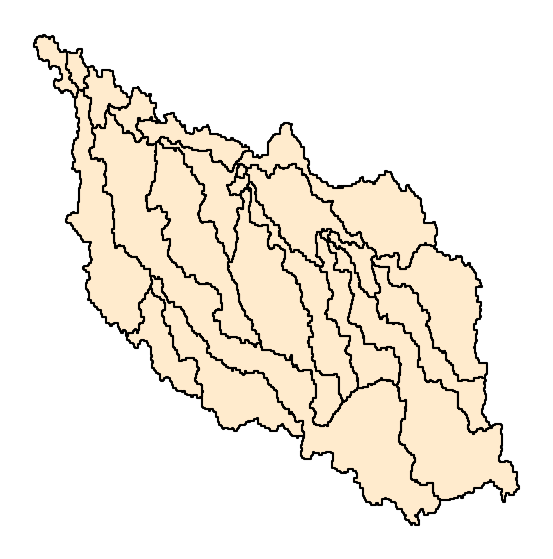

In [ ]:

# Identify initial subbasin containing WSC outlet point

point = Point(wsc_dp.Longitude, wsc_dp.Latitude)
#point = wsc_dp_gdf.geometry
basins_gdf['contains_point'] = basins_gdf.geometry.contains(point, align = False)

# wsc_basins = basins_gdf.sjoin(point, how = 'inner', predicate = 'contains')

wsc_basins = basins_gdf[basins_gdf['contains_point'] == True]
dp = wsc_basins['SubId'].values

# for i, row in basins_gdf.iterrows():
#     if row['contains_point'] == True:
#            dp = row['SubId']
           
print(dp)

# Create list containing inital Manning Canal subbasins and its upstream subbasin
for i, row in basins_gdf.iterrows():
    if row['DowSubId'] == dp:
        sub_select = [row['DowSubId'], row['SubId']]

print(sub_select)

# Add subbasins to Manning Canal list if they are connected to previously added subbasins (via DowSubId field)
n = 0
while n == 0:
    for i, row in basins_gdf.iterrows():
        if row['DowSubId'] in sub_select and row['SubId'] not in sub_select:
            sub_select.append(row['SubId'])
            break
    else:
        n = 1
print(sub_select)

# Create geodataframe containing Manning Canal subbasins
mc_gdf = basins_gdf[basins_gdf['SubId'].isin(sub_select)]

# Plot Manning Canal subbasins
f, ax = plt.subplots(1,1,figsize=(7,7))
mc_gdf.plot(ax=ax, color = 'blanchedalmond', edgecolor = 'black', linewidth = 1.5)
ax.axis('off')

In [309]:
# Write output basinmaker subbasins geodataframe to shapefile
os.getcwd()
mc_gdf.to_file("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs/mc_basinmaker_subbasins.shp")

C:\Users\emilito\AppData\Local\Temp\ipykernel_24068\266407242.py:2: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  mc_gdf.to_file("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs/mc_basinmaker_subbasins.shp")


## Delineate Upper Manning with Whitebox

In [120]:
import sys
!{sys.executable} -m pip install whitebox
import whitebox
wbt = whitebox.WhiteboxTools()

import shapely
import math
import rasterio
import rasterio.plot
from osgeo import gdal

In [347]:
wbt.set_working_dir("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs")

dem = "sr_dem_cgvd28_Resamp_1.tif"
dem_90m = gdal.Warp('sr_dem_cgvd28_90m.tif', dem, dstSRS= 'EPSG:26914', xRes = 90, yRes =-90, resampleAlg='cubic')

.\whitebox_tools.exe --run="BreachDepressionsLeastCost" --wd="\Users\emilito\Documents\PWA\Data\Raw\manning\DEMs" --dem='sr_dem_cgvd28_90m.tif' --output='mc_breachdep_90m.tif' --dist='1000' --min_dist --fill -v --compress_rasters=False

*****************************************
* Welcome to BreachDepressionsLeastCost *
* Powered by WhiteboxTools              *
* www.whiteboxgeo.com                   *
*****************************************


Reading data...
Finding pits: 0%
Finding pits: 1%
Finding pits: 2%
Finding pits: 3%
Finding pits: 4%
Finding pits: 5%
Finding pits: 6%
Finding pits: 7%
Finding pits: 8%
Finding pits: 9%
Finding pits: 10%
Finding pits: 11%
Finding pits: 12%
Finding pits: 13%
Finding pits: 14%
Finding pits: 15%
Finding pits: 16%
Finding pits: 17%
Finding pits: 18%
Finding pits: 19%
Finding pits: 20%
Finding pits: 21%
Finding pits: 22%
Finding pits: 23%
Finding pits: 24%
Finding pits: 25%
Finding pits: 26%
Finding pits: 27%
Finding pits: 28%
Finding pits: 29%
Finding pits: 30%
Finding pits: 31%
Finding pits: 32%
Finding pits: 33%
Finding pits: 34%
Finding pits: 35%
Finding pits: 36%
Finding pits: 37%
Finding pits: 38%
Finding pits: 39%
Finding pits: 40%
Finding pits: 41%
Finding pits: 42%
Finding pits: 43%
Finding pits: 44%
Finding pits: 45%
Finding pits: 46%
Finding pits: 47%
Finding pits: 48%
Finding pits: 49%
Finding pits: 50%
Finding pits: 51%
Finding pits: 52%
Finding pits: 53%
Finding pits: 54%
Find

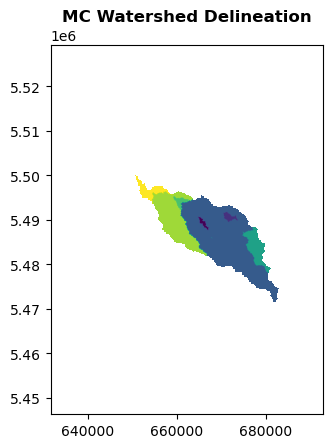

<Axes: title={'center': 'MC Watershed Delineation'}>

In [ ]:
# Set working directory
wbt.set_working_dir("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs")

# Fill depressions in DEM
#wbt.fill_depressions(
    #dem = "sr_dem_cgvd28_Resamp_1.tif",
    #output = "mc_filldep.tif",
    #fix_flats=True,
    #flat_increment=None,
    #max_depth=None
#)

# Breach depressions in DEM
wbt.breach_depressions_least_cost(
    dem = "sr_dem_cgvd28_90m.tif",
    output = "mc_breachdep_90m.tif", 
    dist = 1000, 
    max_cost=None, 
    min_dist=True, 
    flat_increment=None, 
    fill=True
)

# Create flow accumulation raster
wbt.d8_flow_accumulation(
    i = "mc_breachdep_90m.tif", 
    output = "mc_flowaccgrid_90m.tif", 
    out_type="cells", 
    log=False, 
    clip=False, 
    pntr=False, 
    esri_pntr=False
)

# Extract streams from flow accumulation raster
wbt.extract_streams(
    flow_accum='mc_flowaccgrid_90m.tif', 
    output='mc_streams_2000_90m.tif', 
    threshold=2000.000000, 
    zero_background=True, 
)

# Create flow pointer (flow direction) raster
wbt.d8_pointer(
    dem = "mc_breachdep_90m.tif",
    output = "mc_flowpointergrid_90m.tif",
    esri_pntr=False
)

# Snap pour points to stream network
wbt.jenson_snap_pour_points(
    pour_pts = "mc_pp_extract.shp", 
    streams = "mc_streams_2000_90m.tif", 
    output = "mc_pp_snap_2000_90m.shp", 
    snap_dist = 2000.0
)

# Derive watershed areas
wbt.watershed(
    d8_pntr = 'mc_flowpointergrid_90m.tif', 
    pour_pts = 'mc_pp_snap_2000_90m.shp', 
    output = 'mc_watershed_2000_90m.tif', 
    esri_pntr=False
)

# Visualize Manning Canal watershed raster
data_name = "/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs/mc_watershed_2000_90m.tif"
tiff = rasterio.open(data_name)
rasterio.plot.show(tiff, title = "MC Watershed Delineation")

In [ ]:
# Convert raster watershed output to vector polygons
wbt.raster_to_vector_polygons(
    i = 'mc_watershed_90m.tif', 
    output = 'mc_watershed_90m.shp'
)

.\whitebox_tools.exe --run="RasterToVectorPolygons" --wd="\Users\emilito\Documents\PWA\Data\Raw\manning\DEMs" --input='mc_watershed_90m.tif' --output='mc_watershed_90m.shp' -v --compress_rasters=False



*************************************
* Welcome to RasterToVectorPolygons *
* Powered by WhiteboxTools          *
* www.whiteboxgeo.com               *
*************************************
Reading data...
Clumping polygons: 0%
Clumping polygons: 1%
Clumping polygons: 2%
Clumping polygons: 3%
Clumping polygons: 4%
Clumping polygons: 5%
Clumping polygons: 6%
Clumping polygons: 7%
Clumping polygons: 8%
Clumping polygons: 9%
Clumping polygons: 10%
Clumping polygons: 11%
Clumping polygons: 12%
Clumping polygons: 13%
Clumping polygons: 14%
Clumping polygons: 15%
Clumping polygons: 16%
Clumping polygons: 17%
Clumping polygons: 18%
Clumping polygons: 19%
Clumping polygons: 20%
Clumping polygons: 21%
Clumping polygons: 22%
Clumping polygons: 23%
Clumping polygons: 24%
Clumping polygons: 25%
Clumping polygons: 26%
Clumping polygons: 27%
Clumping polygons: 28%
Clumping polygons: 29%
Clumping polygons: 30%
Clumping polygons: 31%
Clumping polygons: 32%
Clumping polygons: 33%
Clumping polygons: 34%

0

## Create BasinMaker Outlet Points

c:\Users\emilito\AppData\Local\anaconda3\envs\gpd_tutorial\lib\site-packages\IPython\core\interactiveshell.py:3448: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):


(-97.00341666732322, -96.46991666698455, 49.35170832966098, 49.70829166312099)

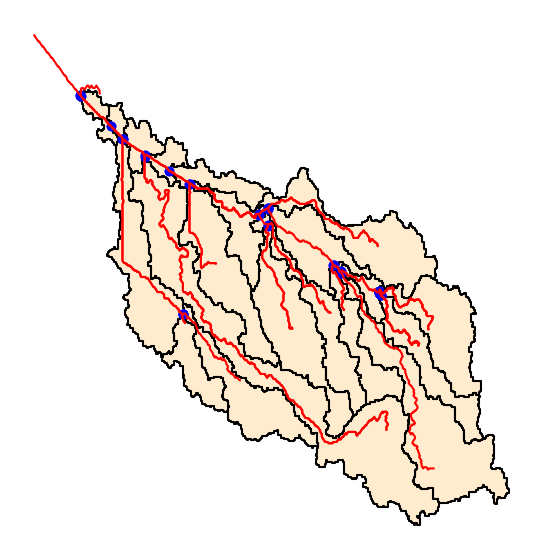

In [305]:
# Read in basinmaker subbasin and rivers shapefiles as geodataframes
os.getcwd()
os.chdir('c:\\Users\\emilito\\Documents\\PWA\\Data\\Raw\\manning\\DEMs')

bm_poly = gpd.read_file('mc_basinmaker_subbasins.shp')
bm_rivers = gpd.read_file('basinmaker_rivers_MC.shp')
#wbt_poly = gpd.read_file('mc_watershed.shp')

# Explode basinmaker geodataframe to split multipolygons into separate polygons
bm_poly_exploded = bm_poly.explode(ignore_index=True)

# Create new dataframe of points where basinmaker rivers intersect with basinmaker subbasins
points_df = gpd.GeoDataFrame(columns=['geometry'])

for i, row in bm_rivers.iterrows():
        for x, row in bm_poly_exploded.iterrows():
            poly_coords = bm_poly_exploded.geometry[x]
            line_coords = bm_rivers.geometry[i]
            polin = LineString(list(poly_coords.exterior.coords))
            #intersection
            pt = polin.intersection(line_coords)
            #print(pt.wkt)
            if pt.wkt != 'LINESTRING EMPTY':
                gdf_to_append = gpd.GeoDataFrame({'geometry': pt.wkt}, index=[0])
                points_df = pd.concat([points_df, gdf_to_append], ignore_index=True)
#print(points_df)

# Convert points dataframe to geodataframe
geometry = points_df['geometry'].map(shapely.wkt.loads)
points_df = points_df.drop('geometry', axis=1)
points_gdf = gpd.GeoDataFrame(points_df, crs="EPSG:4326", geometry=geometry)
#points_gdf = points_gdf.set_crs(epsg=26914, allow_override=True)

# Explode points geodataframe to split multipoints into separate points
points_gdf_exploded = points_gdf.explode(ignore_index=True)

# Extract basinmaker rivers that intersect with basinmaker subbasins
bm_rivers_intersect = gpd.sjoin(bm_rivers, bm_poly_exploded, op='intersects')

# Plot basinmaker subbasins, rivers, and outlet points
f, ax = plt.subplots(1,1,figsize=(7,7))
bm_poly_exploded.plot(ax=ax, color = 'blanchedalmond', edgecolor = 'black', linewidth = 1.5)
points_gdf.plot(ax=ax, color = 'blue', edgecolor = 'blue')
bm_rivers_intersect.plot(ax=ax, color = 'red', edgecolor = 'red', linewidth = 1.5)
ax.axis('off')


In [283]:
# Write exploded basinmaker geodataframes to shapefiles
bm_poly_exploded.to_file("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs/bm_poly_exploded.shp")
points_gdf_exploded.to_file("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs/bm_pp.shp")